---
title: "Smith and Ewart (1948): emulsion polymerisation kinetics and particle number"
description: "Whether Smith and Ewart's particle-number law N = k (rho/mu)^(2/5) (a_s S)^(3/5), its exponents and its bracket 0.37 < k < 0.53, follow from the paper's own premises, and over what part of the paper's own parameter space its Case 2 premise (half a radical per particle) holds."
categories: [sec:J, struct:S1, struct:S11, tier:T0, data:tier0, phase:liquid-liquid]
date: 2026-11-24
---

# Smith and Ewart (1948): emulsion polymerisation kinetics and particle number

**Catalog ID:** `J5.6` · **Structures:** `S1` (algebraic and recursion balances), `S11`
(population balance) · **Tier:** T0

Smith and Ewart wrote the steady balance for the number of latex particles that hold
$n$ radicals, solved it in three limits, and, assuming the middle limit (Case 2, half a
radical per particle, so that every particle grows at the same rate), bounded the number
of particles formed while soap micelles last between two capture assumptions. The
result, $N = k\,(\rho/\mu)^{2/5}(a_s S)^{3/5}$ with $0.37 < k < 0.53$, is the best-known
formula of emulsion polymerisation. The paper prints no physical values; every printed
number is a pure constant. This page asks whether each printed constant, the exponents
and the bracket follow exactly from the paper's own premises, and over what part of the
paper's own $(\alpha, m)$ space the Case 2 premise holds when eq. 1 is solved without its
limiting approximations.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.27.8"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "J5.6-smith-ewart-emulsion-polymerisation"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. pymrm contributes the Stage I population balance (upwind convection,
# divergence, newton) and the checks (find_roots, observed_orders); the closed forms are
# scipy (Bessel, Gamma) and exact rational arithmetic.
import contextlib
import io
import math
import re
from dataclasses import dataclass, field, replace
from fractions import Fraction

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.interpolate import CubicSpline
from pymrm.checks import find_roots, observed_orders
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta
from model import (LAW, STAGE, Law, Stage, StageIPBE, appendix_nbar, appendix_series,
                   dist, dslope_da, equation0_residual, exact_series, mittag_leffler,
                   nbar_closed, nmax_for, recursion, slope_closed, stage_closed, stats)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        return format(v[name], fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))

## Background

In an emulsion polymerisation, radicals formed in the water enter monomer-swollen soap
micelles and latex particles, where the polymer grows. Smith and Ewart (1948) split
the problem in two. Part I takes the particles as given and asks how many radicals each
one holds at steady state; entry, desorption and mutual termination inside a particle
set the distribution. Writing out a general solution, they say, "would appear to be
difficult" (p. 593), so they treat three limits: Case 1, few radicals per particle;
Case 2, about one half; Case 3, many. Case 2 is the one "which appears to apply to the
emulsion polymerization of styrene under normal conditions" (p. 595). Part II assumes
Case 2, so that every particle grows at the same constant volume rate $\mu$, and counts
the particles formed while micelles remain. Two idealised capture rules bracket the
count: all radicals enter micelles while any are left (too many particles), or
micelles and particles catch radicals in proportion to their area (too few). "The actual
situation should lie between that represented by Eqs. (26) and (26a)" (p. 599).

This page complements `J5.3` (bulk free-radical kinetics and the gel effect): here the
radicals are compartmentalised in particles, and particles are formed. Not covered:
molecular weight (pp. 595 and 596), the water-phase kinetics of Case 1 (eqs. 3 to 6 and
9, checked as algebra only) and any experiment (the paper prints none: "The
application of this to experimental data will be discussed in a future paper", p. 599).
The page also does not test where any real system lies on the map, nor whether real
particle numbers fall inside the bracket.

## The published model

**Part I, eq. 1** (p. 593). With $N_n$ the number of particles (per cm$^3$ of water)
holding $n$ radicals, entry rate $\rho'/N$ per particle, desorption $k_0 a n/v$ and
termination events $k_t n(n-1)/v$ (each removes two radicals; p. 593: "the factor of 2
arises from the fact that two free radicals are destroyed for each event of
termination"), the steady state is

$$N_{n-1}\frac{\rho'}{N} + N_{n+1}\frac{k_0 a (n+1)}{v} + N_{n+2}\frac{k_t (n+2)(n+1)}{v}
  = N_n\Big[\frac{\rho'}{N} + \frac{k_0 a n}{v} + \frac{k_t n (n-1)}{v}\Big].$$

The page writes it in two groups, $\alpha = \rho' v/(N k_t) = 1/\beta$ (the paper's
$\beta = k_t N/(v\rho')$, p. 595) and $m = k_0 a/k_t$, with $p_n = N_n/N$:
$0 = \alpha(p_{n-1}-p_n) + m\big((n+1)p_{n+1} - n p_n\big) + (n+2)(n+1)p_{n+2} - n(n-1)p_n$.
The rate per cm$^3$ is $k_p(M)\,N\,\bar n$ with $\bar n = \sum n p_n$ (eq. 2a). The limits:
Case 1, $\bar n = \alpha/m$ for $\alpha \ll m$ (eq. 2); Case 2, $\bar n = 1/2$ for
$k_0 a/v \ll \rho'/N < k_t/v$, i.e. $m \ll \alpha < 1$ (eqs. 10 and 15); Case 3,
$\bar n = (\alpha/2)^{1/2}$ for $\alpha \gg 1$ (eq. 17). For Case 2 the paper also gives,
at $k_0 = 0$, $N_2 = N_0/2\beta$ (exact), the approximation (13)
$N_{n-1}/N_n = 1 + \beta n(n-1)$ (Appendix I) and the series (14)
$n_T = (N/2)(1 + 1/\beta - 1/3\beta^2 + \cdots)$.

**Closed form (later work, not Smith and Ewart's).** The generating function of $p_n$
obeys $(1+x)F'' + mF' - \alpha F = 0$, whose solution regular at $x = -1$ gives
$\bar n = (a/4)\,I_m(a)/I_{m-1}(a)$ with $a = \sqrt{8\alpha}$, the result of Stockmayer
(1957) for $m = 0$ and O'Toole (1965) in general. The page uses it as the exact solution
of eq. 1 and checks it against the truncated recursion. The local slope
$s = d\ln\bar n/d\ln\alpha = 1 - m + (a/2)(1/R - R)$, $R = I_m(a)/I_{m-1}(a)$, is 1 in
Case 1 and 1/2 in Case 3; a Case 2 plateau is where it is near zero.

**Part II.** Soap $S$ (g per cm$^3$ water) covers $a_s$ cm$^2$ per gram, on micelles or
on particles (eq. 20). A particle born at $\tau$ has area
$a = [(4\pi)^{1/2} 3\mu(t-\tau)]^{2/3} = \theta (t-\tau)^{2/3}$ (eqs. 22 to 24, a sphere
growing at constant $dv/dt = \mu$, the Case 2 premise). Upper bound: $dN/dt = \rho$ while
micelles exist (eq. 21), so $A_p = (3/5)\rho\theta t^{5/3}$, micelles vanish at
$t_1 = (5a_sS/3\rho\theta)^{3/5}$ and $N = \rho t_1 = 0.53(\rho/\mu)^{2/5}(a_sS)^{3/5}$
(eq. 26). Lower bound: $dN/dt = \rho(1 - A_p/a_sS)$ (eq. 27) with
$A_p = \theta\int_0^t (t-\tau)^{2/3}(dN/d\tau)d\tau$ (eq. 25a), a Volterra equation (28)
whose solution is the series (29), $dN/dt = \rho\sum y^n/\Gamma(1 + 5n/3)$, with
$y = -(4\pi)^{1/3}3^{2/3}\Gamma(5/3)\rho\mu^{2/3}t^{5/3}/a_sS = -4.36\,\rho\mu^{2/3}t^{5/3}/a_sS$
(eq. 30); the flux vanishes at $y_1 = -2.13$, giving $t_1 = 0.650\,\mu^{-2/5}(a_sS/\rho)^{3/5}$
and $N = 0.370(\rho/\mu)^{2/5}(a_sS)^{3/5}$ (eq. 26a). The page names the series of (29)
the Mittag-Leffler function $E_{5/3}(y)$ and that of (26a) $E_{5/3,2}(y_1)$.

| symbol | meaning | code |
|---|---|---|
| $\alpha = 1/\beta$ | entry over termination, $\rho' v/(N k_t)$ | `alpha` |
| $m$ | desorption over termination, $k_0 a/k_t$ | `m` |
| $\bar n$ | radicals per particle | `nbar` |
| $s$ | $d\ln\bar n/d\ln\alpha$ | `slope_closed` |
| $y, y_1$ | argument of (29), its root | `y1` |
| $k$ | constant of (26), (26a) | `k_upper`, `k_lower` |
| $t^\ast$ | time scale $(a_sS/\rho\theta)^{3/5}$ | scaled time 1 |

## Parameters and assumptions

There are no physical parameters: the paper prints none. Part I works in $\alpha$ and
$m$; Part II in the scaling $t^\ast = (a_sS/\rho\theta)^{3/5}$, in which (28) becomes
$f(t) = 1 - \int_0^t (t-\tau)^{2/3} f(\tau)\,d\tau$ for $f = (dN/dt)/\rho$, so that
$f = E_{5/3}(-\Gamma(5/3)t^{5/3})$ and every Stage I number is a pure constant. Units
follow from the paper's rate expressions (it states none): cgs per cm$^3$ of water.

- **A1 test condition T**: $\alpha = 0.1$ ($\beta = 10$), $m = 0.01$, for the check values.
- **A2 thresholds** of "Case $i$ holds": within 10 % of its limit (and 1 % for Case 2);
  the plateau: slope down to 0.1. These are the page's choices; $m = 1/2$ below is not.
- **A3 eq. 8** is read with re-entry of desorbed radicals, $\alpha = \alpha_0 + m\bar n$ with
  $\alpha_0 = \rho v/(N k_t)$ (the paper equates termination in particles with the formation
  rate $\rho$ but writes eq. 2 with the entry rate $\rho'$; it does not say this).
- **A4 the map** is capped at $m \le 10$ and $\alpha \le 10^4$ (scaled Bessel functions and
  the recursion's size), and no boundary is extrapolated past it.

In [3]:
PN = load_data("smith-ewart-1948-printed-numbers.csv", page=PAGE, dtype=str, keep_default_na=False)
print(cite_data(load_meta("smith-ewart-1948-printed-numbers.csv", page=PAGE)))


def printed(pn, item):
    """A printed entry, as the string printed."""
    return pn.loc[pn["item"] == item, "printed"].iloc[0]


def num(pn, item):
    """A printed number as a float (fractions read exactly)."""
    return float(Fraction(printed(pn, item)))


def half_units(pn, item, exact):
    """Distance of an exact value from a printed entry in half-units of its last digit."""
    s = printed(pn, item)
    dec = len(s.split(".")[1]) if "." in s else 0
    return abs(exact - float(s)) / (0.5 * 10.0 ** (-dec))


ALPHA_T, M_T = 0.1, 0.01
M_MAP = (0.0, 1e-3, 1e-2, 0.1, 0.5, 1.0, 10.0)
LADDER = (1600, 3200, 6400, 12800, 25600)
T_END = {"upper": 1.40, "lower": 1.71}     # scaled march horizons, past each t_1


M_ASYM, ALPHA_ASYM = 0.3, 1e10      # the large-alpha asymptote of the slope is checked here


@dataclass(frozen=True)
class Cfg:
    """Everything the study reads; every break row changes one field."""
    pn: object = field(default_factory=lambda: PN)
    law: Law = LAW                 # Part I rate laws
    stage: Stage = STAGE           # Stage I premises
    nmax_cap: int = None           # n_max forced on every recursion
    comp_alpha: float = 1.0        # alpha factor of the recursion's round-off companion
    reentry: bool = True           # eq. 8 with re-entry of desorbed radicals (A3)
    lim_alpha: float = 1e-8        # alpha of the Case 1 and Case 2 limit checks
    weights: str = "exact"         # PBE cell weights
    lag: bool = False              # PBE inflow from the previous step
    inflow_defect: float = 0.0     # PBE inflow times (1 + c dv^(1/2))
    ladder: tuple = LADDER
    comp_scale: float = 1.0        # inflow factor of the PBE round-off companion
    inflow_scale: float = 1.0      # PBE inflow factor (a defect when not 1)
    scan_n: int = 25               # number of m values in the plateau scan, 1e-3 to 10


C0 = Cfg()
say("Printed Stage I constants (strings): eq. 26 <<a>>, eq. 30 <<b>>, $y_1$ = <<c>>, "
    "$t_1$ constant <<d>>, eq. 26a <<e>>; bracket <<f>> < $k$ < <<g>>; exponents <<h>>, <<i>>, "
    "<<j>>; coefficients of (14) <<k>>, <<l>>, <<n>>.",
    a=printed(PN, "k_upper_eq26"), b=printed(PN, "c_y_eq30"), c=printed(PN, "y1"),
    d=printed(PN, "t1_const"), e=printed(PN, "k_lower_eq26a"), f=printed(PN, "k_bracket_lo"),
    g=printed(PN, "k_bracket_hi"), h=printed(PN, "exp_aS"), i=printed(PN, "exp_rho"),
    j=printed(PN, "exp_mu"), k=printed(PN, "eq14_c0"), l=printed(PN, "eq14_c1"),
    n=printed(PN, "eq14_c2"))

Smith, W. V.; Ewart, R. H. (1948) — The Journal of Chemical Physics 16, 592-599 — doi:10.1063/1.1746951 — table


Printed Stage I constants (strings): eq. 26 0.53, eq. 30 4.36, $y_1$ = -2.13, $t_1$ constant 0.650, eq. 26a 0.370; bracket 0.37 < $k$ < 0.53; exponents 3/5, 2/5, -2/5; coefficients of (14) 1, 1, -1/3.

## The data

One file, `smith-ewart-1948-printed-numbers.csv` with its `.meta.yaml` sidecar: the
printed constants, exponents, series coefficients and recursion expressions, kept as the
strings printed and read from 300 ppi page images (the scan's text layer garbles
formulas). The paper has no table and no data figure, so nothing is digitised, and no
dataset is borrowed from another page. A second file, `check_values.csv`, holds values
of the page's quantities at the test condition computed by a separate route (see
below); it is not data about the world.

Agreement with a printed constant is a count in half-units of its last printed digit:
1 means the exact value would round to a neighbouring entry.

## PyMRM implementation

Part I is linear algebra and special functions: the closed form with scaled Bessel
functions (`scipy.special.ive`), the truncated recursion as a sparse linear solve (it is
linear, so no Newton iteration), exact power series in $\alpha$ with Python fractions.
Thresholds and band edges are roots by `pymrm.checks.find_roots`, each required to be
the only root on its physical range; the minimum of the slope is the root of its
analytic derivative.

Part II is closed form (Mittag-Leffler series) and, as a second route that does not use
eqs. 25a and 28, a population balance in particle volume (`model.StageIPBE`): in scaled
variables $\partial n/\partial t + \partial n/\partial v = 0$ on $[0, 2]$, the inflow
$n(t,0) = 1$ (upper bound) or $1 - A_p$ (lower bound), $A_p = \sum w_i n_i$ with $w_i$
the exact cell integral of $v^{2/3}$. `construct_convflux_upwind` gives the upwind flux
with the inflow as an external boundary value (`shapes_d`, so the matrix is assembled
once), `construct_div` the divergence ($\nu = 0$), and each implicit Euler step
(CFL 1) is solved by `pymrm.newton` with the analytic Jacobian: bidiagonal plus one dense
row from the nonlocal inflow, factorised once with the cells numbered from the right so
that the dense row fills nothing. The end of Stage I is a root in time of a cubic spline
through the step values, extrapolated in the step on a five-level ladder after its order
is measured (`pymrm.checks.observed_orders`).

### Check values

Before any claim, the page's functions are checked against values computed by a second
route (numpy and scipy, written apart from this page) at T and at the Stage I and
population-balance test points.

In [4]:
def one_root(f, lo, hi, what, log=True, n_scan=48, xtol=1e-14):
    """The single root of f on [lo, hi], or raise."""
    r = find_roots(f, lo, hi, n_scan=n_scan, log=log, xtol=xtol)
    if len(r["roots"]) != 1:
        raise ValueError(f"{what}: {r['message']} on [{lo:g}, {hi:g}]")
    return r["roots"][0]


def nb(alpha, m, cfg):
    return dist(alpha, m, cfg.law)[0]


def smin(m_eff, a_lo=math.sqrt(8e-8), a_hi=math.sqrt(8e4)):
    """Minimum of the slope over alpha in [1e-8, 1e4] at m_eff (root of ds/da), or None."""
    r = find_roots(lambda a: dslope_da(a, m_eff), a_lo, a_hi, n_scan=96, log=True, xtol=1e-14)
    # a plateau is a minimum below the Case 3 slope 1/2; sign changes of ds/da where the
    # slope is within 1e-6 of 1/2 are round-off of a flat tail (seen at m = 1/2 exactly)
    roots = [a for a in r["roots"] if slope_closed(a * a / 8.0, m_eff) < 0.5 - 1e-6]
    if not roots:
        return None
    if len(roots) != 1:
        raise ValueError(f"slope has {len(roots)} minima below 1/2 at m = {m_eff:g}")
    a = roots[0]
    return a * a / 8.0, float(slope_closed(a * a / 8.0, m_eff))


PBE_CACHE = {}


def pbe_run(nc, bound, cfg, factor="reversed", scale=1.0, t_end=None):
    """One Stage I march (cached by its arguments)."""
    st = cfg.stage
    scale = scale * cfg.inflow_scale
    key = (nc, bound, st.q, st.capture, cfg.weights, cfg.lag, cfg.inflow_defect, factor, scale,
           t_end or T_END[bound])
    if key not in PBE_CACHE:
        m = StageIPBE(nc, bound, q=st.q, weights=cfg.weights, lag=cfg.lag, capture=st.capture,
                      inflow_defect=cfg.inflow_defect, factor=factor, inflow_scale=scale)
        PBE_CACHE[key] = m.march(t_end or T_END[bound])
    return PBE_CACHE[key]


def stage_end(h):
    """t_1 (A_p = 1, a root of a cubic spline through the step values) and N(t_1)."""
    t, ap, n = h["t"], h["Ap"], h["N"]
    above = np.nonzero(ap >= 1.0)[0]
    if above.size == 0:
        raise ValueError("A_p does not reach a_s S inside the march")
    j = int(above[0])
    w = slice(max(j - 6, 0), min(j + 6, t.size))
    sp = CubicSpline(t[w], 1.0 - ap[w])
    t1 = one_root(sp, t[j - 1], t[j], "stage end", log=False, n_scan=8, xtol=1e-15)
    return t1, float(CubicSpline(t[w], n[w])(t1))


def pbe_point(nc, cfg, M=None, prefix=None):
    """A_p(1), N(1) and the stage end on one grid, both bounds."""
    out = {}
    k1 = nc // 2                                       # t = 1 at step n_c/2 (dt = 2/n_c)
    for b in ("upper", "lower"):
        h = pbe_run(nc, b, cfg)
        out[f"{b}_Ap1"] = h["Ap"][k1]
        out[f"{b}_N1"] = h["N"][k1]
        if b == "lower" and cfg.stage.capture != "micelle" and np.max(np.abs(h["N"])) == 0.0:
            out[f"{b}_t1"] = out[f"{b}_Nt1"] = float("nan")      # no particle is ever formed
            out["_noroot"] = True
            continue
        try:
            out[f"{b}_t1"], out[f"{b}_Nt1"] = stage_end(h)
        except ValueError:                # a defect that moves the stage end past the march
            out[f"{b}_t1"] = out[f"{b}_Nt1"] = float("nan")
        if b == "upper":
            out["upper_N_conservation"] = float(np.max(np.abs(h["N"] - h["t"] * (1 + cfg.inflow_defect * math.sqrt(2.0 / nc)))))
    return out


def check_values(M):
    """The page's value of every check-value row, from M and direct calls."""
    cv = {k: M[v] for k, v in {
        "T_nbar": "r1_T_nbar", "T_p0": "r1_T_p0", "T_p1": "r1_T_p1",
        "T_eq7_termination_ratio": "r1_eq7_ratio", "T_eq7_ratio_limit_alpha0": "r1_eq7_limit",
        "T_nbar_trunc_err_nmax3": "v1_trunc_err_3", "T_nbar_trunc_err_nmax4": "v1_trunc_err_4",
        "T_nbar_trunc_err_nmax5": "v1_trunc_err_5", "T_m0_nbar": "r2_exact_nbar_beta10",
        "T_m0_p2_over_p0": "r2_p2_over_p0", "T_m0_p1_over_p0_exact": "r2_p1_over_p0_exact",
        "SE_p1_over_p0_beta10": "r2_p1_over_p0_paper", "SE_series14_beta10": "r2_series14_beta10",
        "SE_appendix_nbar_beta10": "r2_appendix_beta10", "SE_appendix_nbar_beta1": "r2_appendix_beta1",
        "exact_nbar_beta1": "r2_exact_nbar_beta1", "beta_at_nbar_0p55_m0": "r1_beta_10pct_m0",
        "beta_at_nbar_0p505_m0": "r1_beta_1pct_m0", "alpha_case3_10pct_m0": "r1_alpha_case3_10pct_m0",
        "T_alpha_case1_10pct": "r1_alpha_case1_10pct", "T_alpha_nbar_0p45": "r1_alpha_nbar_045",
        "T_alpha_nbar_0p55": "r1_alpha_nbar_055", "T_slope": "r1_T_slope",
        "m_at_case2_slope_0p1": "r1_m_plateau_01", "T_alpha_nbar_m_half": "v2_nbar_m_half",
        "T_alpha_nbar_m_three_half": "v2_nbar_m_three_half", "T_alpha_slope_m_half": "v2_slope_m_half",
        "T_m_case3_offset_alpha1e4": "v2_case3_offset", "T_m_case3_offset_limit": "v2_case3_offset_limit",
        "T_eq8_alpha": "r1_eq8_alpha", "T_eq8_nbar": "r1_eq8_nbar",
        "T_eq8_ratio_to_sqrt_alpha0_over_2m": "r1_eq8_ratio", "c_y_eq30": "r3_c_y",
        "y1": "r4_y1", "E_53_2_at_y1": "r4_bracket", "t1_const_lower": "r4_t1_const",
        "k_lower": "r4_k_lower", "k_upper": "r3_k_upper", "ts1_upper_scaled": "r3_ts1_upper",
        "ts1_lower_scaled": "r4_ts1_lower", "Ns_lower_scaled": "r4_Ns_lower",
        "ratio_t1_lower_over_upper": "r4_ratio_t1", "ratio_k_lower_over_upper": "r4_ratio_k",
        "t1_const_from_printed_2p13_4p36": "r4_t1_const_from_printed",
        "k_lower_from_printed_0p650_y1": "r4_k_lower_from_printed",
        "hu_c_y_4p36": "r3_hu_c_y", "hu_y1_2p13": "r4_hu_y1", "hu_t1_const_0p650": "r4_hu_t1_const",
        "hu_k_lower_0p370": "r4_hu_k_lower", "hu_k_upper_0p53": "r3_hu_k_upper",
        "bracket26a_terms_to_n4": "r4_bracket_n4", "bracket26a_terms_to_n3": "r4_bracket_n3",
        "bracket26a_terms_to_n2": "r4_bracket_n2", "y1_eq29_terms_to_n4": "r4_y1_n4",
        "At1_lower_scaled": "r5_lower_Ap1_exact", "Nt1_lower_scaled": "r5_lower_N1_exact",
        "pbe_nc1600_upper_Ap_t1": "r5_1600_upper_Ap1", "pbe_nc1600_lower_Ap_t1": "r5_1600_lower_Ap1",
        "pbe_nc1600_lower_N_t1": "r5_1600_lower_N1"}.items()}
    return cv

### The study

`study(cfg, parts)` computes every number the page reports; the break table reruns it
with one defect at a time, and only the parts the defect reaches.

In [5]:
def part_p1(cfg, M):
    """R1, R2 and V2: Part I in closed form, roots, plateau, eqs. 7, 8, 14 and Appendix I."""
    law, pn = cfg.law, cfg.pn
    lin = law.desorb == "linear"
    nT, p0T, p1T = dist(ALPHA_T, M_T, law)
    M["r1_T_nbar"], M["r1_T_p0"], M["r1_T_p1"] = nT, p0T, p1T
    M["r1_T_rate_over_case2"] = nT / 0.5
    M["r1_eq7_ratio"] = (ALPHA_T - M_T * nT) / (2 * ALPHA_T * p1T)
    M["r1_eq7_limit"] = 1.0 / (1.0 + M_T)
    if lin:
        M["r1_T_slope"] = float(slope_closed(ALPHA_T, M_T, law))
    # case boundaries (A2), every one the single root on its range
    a55 = one_root(lambda a: nb(a, 0.0, cfg) - 0.55, 1e-5, 1.0, "nbar = 0.55, m = 0")
    a505 = one_root(lambda a: nb(a, 0.0, cfg) - 0.505, 1e-5, 1.0, "nbar = 0.505, m = 0")
    M["r1_beta_10pct_m0"], M["r1_beta_1pct_m0"] = 1 / a55, 1 / a505
    M["r1_beta_10pct_over_condition"] = M["r1_beta_10pct_m0"] / num(pn, "beta_condition")
    M["r1_alpha_case3_10pct_m0"] = one_root(
        lambda a: nb(a, 0.0, cfg) / math.sqrt(a / 2) - 1.1, 1e-2, 1e4, "Case 3 10 %, m = 0")
    M["r1_alpha_case1_10pct"] = one_root(
        lambda a: nb(a, M_T, cfg) * M_T / a - 0.9, 1e-8, 1e-1, "Case 1 10 %, m = 0.01")
    M["r1_alpha_nbar_045"] = one_root(lambda a: nb(a, M_T, cfg) - 0.45, 1e-6, 1e2, "nbar = 0.45")
    M["r1_alpha_nbar_055"] = one_root(lambda a: nb(a, M_T, cfg) - 0.55, 1e-6, 1e2, "nbar = 0.55")
    M["r1_case2_band_decades"] = math.log10(M["r1_alpha_nbar_055"] / M["r1_alpha_nbar_045"])
    M["r1_alpha_case3_10pct"] = one_root(
        lambda a: nb(a, M_T, cfg) / math.sqrt(a / 2) - 1.1, 1e-2, 1e4, "Case 3 10 %, m = 0.01")
    if lin:
        mi = smin(M_T / law.term)
        M["r1_T_min_slope"], M["r1_T_alpha_min_slope"] = mi[1], mi[0] * law.term
        M["r1_m_plateau_01"] = law.term * one_root(
            lambda me: smin(me)[1] - 0.1, 1e-4, 0.3, "plateau slope 0.1", n_scan=24, xtol=1e-15)
        grid = np.geomspace(1e-3, 10.0, cfg.scan_n)
        has = [smin(mm / law.term) is not None for mm in grid]
        M["r1_scan_n_m"] = len(grid)
        M["r1_scan_n_below_half"] = int(np.sum(grid < 0.5))
        M["r1_scan_n_at_or_above_half"] = int(np.sum(grid >= 0.5))
        M["r1_scan_n_min"] = int(sum(has))
        M["r1_scan_n_min_at_or_above_half"] = int(sum(h for h, mm in zip(has, grid) if mm >= 0.5))
        M["_scan"] = (grid, has)
        # the slope at m = 0.3 (between the plateau threshold and 1/2) and the large-alpha
        # asymptote s = 1/2 + (2m - 1)/(4a), a = sqrt(8 alpha), checked at alpha = 1e10
        M["r1_m03_min_slope"] = smin(M_ASYM / law.term)[1]
        dev = float(slope_closed(ALPHA_ASYM, M_ASYM, law)) - 0.5
        M["r1_asym_dev"] = dev
        M["r1_asym_gap"] = abs(dev / ((2 * M_ASYM - 1) / (4 * math.sqrt(8 * ALPHA_ASYM))) - 1)
    # eq. 8 (A3)
    a0 = 1e-6
    if cfg.reentry:
        a8 = one_root(lambda a: a - a0 - M_T * nb(a, M_T, cfg), a0, 1.0, "eq. 8 alpha")
    else:
        a8 = a0
    M["r1_eq8_alpha"], M["r1_eq8_nbar"] = a8, nb(a8, M_T, cfg)
    M["r1_eq8_ratio"] = M["r1_eq8_nbar"] / math.sqrt(a0 / (2 * M_T))
    # R2: eq. 14 and Appendix I (m = 0)
    ex = exact_series(4, Fraction(law.term))
    for k in range(1, 5):
        M[f"r2_exact_c{k}"] = float(ex[k])
    app = appendix_series(4)
    for k in (1, 2, 3):
        M[f"r2_appendix_c{k}"] = float(app[k])
    pc = [Fraction(printed(pn, f"eq14_c{k}")) for k in range(3)]
    M["r2_n_printed_coef_exact"] = int(sum(pc[k] == ex[k] for k in range(3)))
    M["r2_n_appendix_coef_exact"] = int(sum(app[k] == ex[k] for k in range(4)))
    _, p = nmax_for(ALPHA_T, 0.0, law)
    M["r2_exact_nbar_beta10"] = nb(ALPHA_T, 0.0, cfg)
    M["r2_p2_over_p0"] = p[2] / p[0]
    M["r2_p1_over_p0_exact"] = p[1] / p[0]
    M["r2_appendix_beta10"], M["r2_p1_over_p0_paper"] = appendix_nbar(10.0)
    M["r2_p1_over_p0_gap"] = M["r2_p1_over_p0_paper"] / M["r2_p1_over_p0_exact"] - 1
    s14 = lambda be: 0.5 * float(sum(pc[k] / Fraction(be) ** k for k in range(3)))
    M["r2_series14_beta10"] = s14(10)
    M["r2_appendix_beta1"] = appendix_nbar(1.0)[0]
    M["r2_exact_nbar_beta1"] = nb(1.0, 0.0, cfg)
    M["r2_exact_beta1_excess"] = M["r2_exact_nbar_beta1"] / 0.5 - 1
    betas = np.geomspace(1.0, 1000.0, 61)
    ex_b = np.array([nb(1 / b, 0.0, cfg) for b in betas])
    e_app = np.array([appendix_nbar(b)[0] for b in betas]) / ex_b - 1
    e_ser = np.array([s14(Fraction(b).limit_denominator(10**9)) for b in betas]) / ex_b - 1
    M["r2_appendix_err_beta1"], M["r2_series_err_beta1"] = e_app[0], e_ser[0]
    M["r2_appendix_err_beta10"] = M["r2_appendix_beta10"] / M["r2_exact_nbar_beta10"] - 1
    M["r2_series_err_beta10"] = M["r2_series14_beta10"] / M["r2_exact_nbar_beta10"] - 1
    M["r2_errors_decrease"] = bool(np.all(np.diff(np.abs(e_app)) < 0) and np.all(np.diff(np.abs(e_ser)) < 0))
    M["_r2"] = (betas, e_app, e_ser)
    # V2: limits in closed form
    la = cfg.lim_alpha
    M["v2_case1_limit_gap"] = abs(nb(la, M_T, cfg) * M_T / la - 1)
    M["v2_case2_limit_gap"] = abs((nb(la, 0.0, cfg) - 0.5) / (la / 2) - 1)
    M["v2_case3_offset"] = nb(1e4, M_T, cfg) - math.sqrt(1e4 / 2)
    M["v2_case3_offset_limit"] = (1 - 2 * M_T) / 8
    M["v2_nbar_m_half"] = nb(ALPHA_T, 0.5, cfg)
    M["v2_nbar_m_three_half"] = nb(ALPHA_T, 1.5, cfg)
    a = math.sqrt(8 * ALPHA_T)
    M["v2_m_half_gap"] = abs(M["v2_nbar_m_half"] / (a / 4 * math.tanh(a)) - 1)
    M["v2_m_three_half_gap"] = abs(M["v2_nbar_m_three_half"] / (a / 4 * (1 / math.tanh(a) - 1 / a)) - 1)
    if lin:
        M["v2_slope_m_half"] = float(slope_closed(ALPHA_T, 0.5, law))
        M["v2_slope_m_half_gap"] = abs(M["v2_slope_m_half"] / (0.5 * (1 + 2 * a / math.sinh(2 * a))) - 1)


def part_rec(cfg, M):
    """V1: the truncated recursion against the closed form, n_max table, companion."""
    law, cap = cfg.law, cfg.nmax_cap
    nmax, p = nmax_for(ALPHA_T, M_T, law, cap=cap)
    s = stats(p)
    nT, p0T, p1T = dist(ALPHA_T, M_T, law)
    M["v1_T_nmax"] = nmax
    M["v1_T_gap"] = max(abs(s["nbar"] / nT - 1), abs(s["p0"] / p0T - 1), abs(s["p1"] / p1T - 1))
    M["v1_sum_p"] = abs(s["sum"] - 1)
    M["v1_radical_balance"] = abs(ALPHA_T * (1 - p[-1]) - M_T * s["nbar"] - 2 * s["S2"])
    res = [abs(equation0_residual(p, ALPHA_T, M_T, law))]
    tab = {}
    for k in range(3, 9):
        pk = recursion(ALPHA_T, M_T, k if cap is None else min(k, cap), law)
        res.append(abs(equation0_residual(pk, ALPHA_T, M_T, law)))
        tab[k] = stats(pk)["nbar"] - nT
    M["v1_eq0_residual_max"] = max(res)
    for k in (3, 4, 5):
        M[f"v1_trunc_err_{k}"] = tab[k]
    M["v1_trunc_err_8"] = abs(tab[8])
    gaps = []
    for mm in M_MAP:
        for al in np.geomspace(1e-4, 1e4, 17):
            _, pp = nmax_for(al, mm, law, cap=cap)
            gaps.append(abs(stats(pp)["nbar"] / dist(al, mm, law)[0] - 1))
    M["v1_map_gap_max"], M["v1_map_n_points"] = max(gaps), len(gaps)
    _, pb = nmax_for(1e4, M_T, law, cap=cap)
    small = np.nonzero(np.abs(pb) / np.max(np.abs(pb)) < 1e-17)[0]
    small = small[small > np.argmax(pb)]
    M["v1_nmax_alpha1e4"] = int(small[0]) if small.size else pb.size
    pd = recursion(ALPHA_T * cfg.comp_alpha, M_T, nmax, law, method="dense")
    ps = recursion(ALPHA_T, M_T, nmax, law, permc_spec="MMD_AT_PLUS_A")
    M["v1_companion_gap"] = float(np.max(np.abs(pd - ps) / np.max(ps)))


def part_stage(cfg, M):
    """R3, R4: the Stage I constants in closed form, half-units, truncations, exponents."""
    st, pn = cfg.stage, cfg.pn
    c = stage_closed(st, find_roots=find_roots)
    M["_noroot"] = c["noroot"]
    M["r3_c_y"], M["r3_k_upper"], M["r3_ts1_upper"] = c["c_y"], c["k_upper"], c["ts1_upper"]
    M["r3_exp_rho"], M["r3_exp_aS"], M["r3_exp_mu"] = c["exp_rho"], c["exp_aS"], c["exp_mu"]
    x, y, z = c["exp_rho"], c["exp_mu"], c["exp_aS"]
    M["r3_dimension_residual"] = max(abs(-x - y), abs(-3 * x + 3 * y - z + 3))   # s and cm of N
    M["r3_n_exponents_as_printed"] = int(sum(math.isclose(v, num(pn, it), abs_tol=1e-14) for v, it in
                                             ((x, "exp_rho"), (z, "exp_aS"), (y, "exp_mu"))))
    for k, n in (("y1", "r4_y1"), ("bracket", "r4_bracket"), ("t1_const", "r4_t1_const"),
                 ("k_lower", "r4_k_lower"), ("ts1_lower", "r4_ts1_lower"), ("Ns_lower", "r4_Ns_lower"),
                 ("ratio_t1", "r4_ratio_t1"), ("ratio_k", "r4_ratio_k")):
        M[n] = c[k]
    if c["noroot"]:
        M["r4_flux_scan_max"] = c["flux_scan_max"]
    a, q = st.a, st.q
    # half-units against the printed strings (rule 6)
    M["r3_hu_c_y"] = half_units(pn, "c_y_eq30", c["c_y"])
    M["r3_hu_k_upper"] = half_units(pn, "k_upper_eq26", c["k_upper"])
    M["r3_hu_bracket_hi"] = half_units(pn, "k_bracket_hi", c["k_upper"])
    M["r4_ml_last_term"] = mittag_leffler(-3.0, a, tol=st.ml_tol)[1]
    # lower-bound quantities at scaled t = 1
    g = math.gamma(q + 1)
    M["r5_lower_Ap1_exact"] = 1 - float(mittag_leffler(-g, a, tol=st.ml_tol)[0])
    M["r5_lower_N1_exact"] = float(mittag_leffler(-g, a, 2.0, tol=st.ml_tol)[0])
    M["r5_upper_Ap1_exact"] = 1.0 / (q + 1.0)
    # the printed-input chain
    yp, cp = num(pn, "y1"), num(pn, "c_y_eq30")
    M["r4_t1_const_from_printed"] = (-yp / cp) ** (1 / (q + 1))
    M["r4_hu_t1_const_from_printed"] = half_units(pn, "t1_const", M["r4_t1_const_from_printed"])
    M["r4_k_lower_from_printed"] = num(pn, "t1_const") * float(mittag_leffler(yp, a, 2.0, tol=st.ml_tol)[0])
    M["r4_hu_k_lower_from_printed"] = half_units(pn, "k_lower_eq26a", M["r4_k_lower_from_printed"])
    if c["noroot"]:
        return
    M["r4_hu_y1"] = half_units(pn, "y1", c["y1"])
    M["r4_hu_t1_const"] = half_units(pn, "t1_const", c["t1_const"])
    M["r4_hu_k_lower"] = half_units(pn, "k_lower_eq26a", c["k_lower"])
    M["r4_hu_bracket_lo"] = half_units(pn, "k_bracket_lo", c["k_lower"])
    hus = [M["r3_hu_k_upper"], M["r3_hu_c_y"], M["r4_hu_y1"], M["r4_hu_t1_const"], M["r4_hu_k_lower"]]
    M["r34_hu_max"] = max(hus)
    M["r34_n_round"] = int(sum(h < 1 for h in hus))
    M["r34_n_round__margin"] = min(abs(h - 1) for h in hus)
    M["r34_n_printed"] = len(hus)
    # terms of (29) and (26a)
    for K in (2, 3, 4):
        M[f"r4_bracket_n{K}"] = float(mittag_leffler(c["y1"], a, 2.0, nterms=K)[0])
    M["r4_k_lower_n2"] = c["t1_const"] * M["r4_bracket_n2"]
    M["r4_hu_k_lower_n2"] = half_units(pn, "k_lower_eq26a", M["r4_k_lower_n2"])
    ys = {}
    for K in range(2, 12):
        r = find_roots(lambda y: float(mittag_leffler(y, a, nterms=K)[0]), -3.0, 0.0, n_scan=64, xtol=1e-14)
        ys[K] = r["roots"][-1] if r["roots"] else float("nan")   # the root nearest y = 0: the first in time
    M["r4_y1_n4"] = ys[4]
    M["r4_hu_y1_n4"] = half_units(pn, "y1", ys[4])
    ok29 = [K for K in range(2, 12) if half_units(pn, "y1", ys[K]) < 1 and all(
        half_units(pn, "y1", ys[J]) < 1 for J in range(K, 12))]
    M["r4_min_terms_29"] = ok29[0] if ok29 else -1
    ok26 = [K for K in range(1, 12) if all(half_units(
        pn, "k_lower_eq26a", c["t1_const"] * float(mittag_leffler(c["y1"], a, 2.0, nterms=J)[0])) < 1
        for J in range(K, 12))]
    M["r4_min_terms_26a"] = ok26[0] if ok26 else -1
    M["r4_fraction_making_particles"] = c["bracket"]


def pbe_ladder(cfg, M):
    """R5, V3: the population balance on the ladder; orders, extrapolation, companion."""
    vals = {nc: pbe_point(nc, cfg) for nc in cfg.ladder}
    c = stage_closed(cfg.stage, find_roots=find_roots)
    exact = {"upper_Ap1": 1 / (cfg.stage.q + 1), "lower_Ap1": M["r5_lower_Ap1_exact"],
             "lower_N1": M["r5_lower_N1_exact"], "upper_t1": c["ts1_upper"], "upper_Nt1": c["ts1_upper"],
             "lower_t1": c["ts1_lower"], "lower_Nt1": c["Ns_lower"]}
    for key, ex in exact.items():
        o = observed_orders(lambda nc: vals[nc][key], cfg.ladder)
        M[f"v3_{key}_order_min"], M[f"v3_{key}_order_max"] = min(o["orders"]), max(o["orders"])
        M[f"r5_{key}_ext"] = o["extrapolated"]
        M[f"r5_{key}_err_est"] = o["error_estimate"]
        M[f"r5_{key}_ext_gap"] = abs(o["extrapolated"] - ex)
        M[f"_fd_{key}"] = abs(o["values"][-1] - o["values"][-2])
    M["v3_upper_N_conservation"] = max(vals[nc]["upper_N_conservation"] for nc in cfg.ladder)
    M["_vals"] = vals


def part_comp(cfg, M):
    """V3 round-off companion: the finest lower-bound march with the rank-one factorisation."""
    nc = LADDER[-1]
    k1 = nc // 2
    h = pbe_run(nc, "lower", C0)
    hc = pbe_run(nc, "lower", C0, factor="rank_one", scale=cfg.comp_scale, t_end=1.0)
    d = max(abs(hc["Ap"][k1] - h["Ap"][k1]), abs(hc["N"][k1] - h["N"][k1]), 1e-16)
    fd = max(abs(pbe_run(nc, "lower", C0)["Ap"][k1] - pbe_run(nc // 2, "lower", C0)["Ap"][k1 // 2]), 1e-300)
    M["v3_finest_over_roundoff"] = fd / d


ALL = ("p1", "rec", "stage", "pbe1600", "ladder", "comp")


def study(cfg, parts=ALL):
    """Every number the page reports, for one configuration."""
    M = {}
    if "p1" in parts:
        part_p1(cfg, M)
    if "rec" in parts:
        part_rec(cfg, M)
    if {"stage", "pbe1600", "ladder"} & set(parts):
        part_stage(cfg, M)
    if "pbe1600" in parts or "ladder" in parts:
        v = pbe_point(1600, cfg)
        M["_noroot"] = M.get("_noroot", False) or v.pop("_noroot", False)
        for k, x in v.items():
            if k not in ("upper_N_conservation", "upper_N1"):     # N = t for the upper bound: V3
                M[f"r5_1600_{k}"] = x
    if "ladder" in parts:
        pbe_ladder(cfg, M)
    if "comp" in parts:
        part_comp(cfg, M)
    return M


M = study(C0)
CV = check_values(M)
with contextlib.redirect_stdout(io.StringIO()):
    DEV = assert_check_values(CV, page=PAGE)
say("Check values: <<n:d>> of <<t:d>> rows agree, each inside its own tolerance "
    "(rtol 1e-11 to 3.5e-5); worst relative deviation <<w:.1e>>.",
    n=len(DEV), t=len(CV), w=max(abs(v) for v in DEV.values()))

Check values: 59 of 59 rows agree, each inside its own tolerance (rtol 1e-11 to 3.5e-5); worst relative deviation 3.0e-11.

## Results

### R1: the exact distribution and the three cases

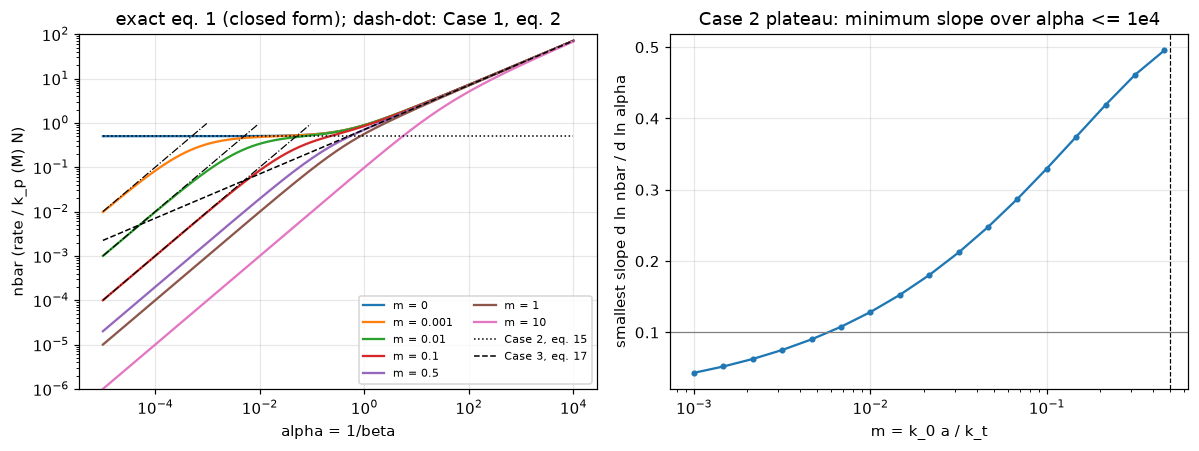

At T ($\alpha$ = 0.1, $m$ = 0.01) the exact $\bar n$ is 0.524187, 1.0484 times the Case 2 value, with $p_0$ = 0.499125 and $p_1$ = 0.477937; the local slope is 0.132398.

**How large $\beta$ must be.** The paper reads "(from (10) $\beta$>1)" (p. 595), calls the approximation of Appendix I satisfactory "when $\beta$>1", and expects $\bar n$ near 1/2 "if $\beta$ is sufficiently large". At $m$ = 0 the exact $\bar n$ is within 10 % of 1/2 only for $\beta \ge$ 9.6723 (9.67 times the value 1 read from eq. 10) and within 1 % for $\beta \ge$ 99.667; at $\beta$ = 1 it is 0.8878, 77.6% above 1/2. Case 3 is within 10 % for $\alpha \ge$ 4.2012 at $m$ = 0 and 4.0532 at $m$ = 0.01; Case 1 within 10 % for $\alpha \le$ 5.6142e-04 at $m$ = 0.01. At $m$ = 0.01 the band where $\bar n$ is within 0.45 to 0.55 runs from $\alpha$ = 0.03294 to 0.14137, 0.633 decades.

**The plateau.** At $m$ = 0.01 the slope falls to 0.12859 at $\alpha$ = 0.07534 (root of the analytic derivative). The smallest slope reaches 0.1 only for $m \le$ 0.005776, so by that threshold Case 2 is already gone above this $m$; at $m$ = 0.3 the smallest slope is 0.4558. Over 25 values of $m$ from 0.001 to 10, 17 have an interior minimum of the slope below 1/2 on $\alpha \le 10^4$: all 17 below $m$ = 1/2 and 0 of the 8 at or above it. Any dip below 1/2 is gone from $m$ = 1/2 on (closed form there, $s = \tfrac12(1 + 2a/\sinh 2a)$, 0.807604 at $\alpha$ = 0.1; none of the scanned $m$ up to 10). The boundary sits at $m$ = 1/2 because the large-$\alpha$ slope is $s = \tfrac12 + (2m - 1)/(4a) + O(a^{-2})$ with $a = \sqrt{8\alpha}$, below 1/2 for $m < 1/2$ and above it for $m > 1/2$; at $m$ = 0.3 and $\alpha$ = 1e+10 it gives $s - 1/2$ = -3.5363e-07, within 2.2e-04 (relative) of the asymptote. This is the paper's "transition from case 1 to case 3 without ever realizing case 2" (p. 596), with the exact boundary at $k_0 a = k_t/2$, where the paper asks only that $k_0a$ "must be much smaller than $k_t$" (p. 596).

**Eqs. 7 and 8.** The ratio of termination in particles to $2(\rho'/N)N_1$ is 0.991325 at T against its $\alpha \to 0$ limit $1/(1+m)$ = 0.990099. Read with re-entry (A3), eq. 8 at $\alpha_0$ = 1e-6 gives $\alpha$ = 7.156762e-05 and $\bar n$ = 7.056762e-03, 0.997977 times $(\alpha_0/2m)^{1/2}$.

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
al = np.geomspace(1e-5, 1e4, 300)
for mm in M_MAP:
    ax[0].loglog(al, nbar_closed(al, mm), label=f"m = {mm:g}")
ax[0].loglog(al, np.full_like(al, 0.5), "k:", lw=1, label="Case 2, eq. 15")
ax[0].loglog(al, np.sqrt(al / 2), "k--", lw=1, label="Case 3, eq. 17")
for mm in (1e-3, 1e-2, 0.1):
    ax[0].loglog(al[al < mm], al[al < mm] / mm, "k-.", lw=0.8)
ax[0].set(xlabel="alpha = 1/beta", ylabel="nbar (rate / k_p (M) N)", ylim=(1e-6, 1e2),
          title="exact eq. 1 (closed form); dash-dot: Case 1, eq. 2")
ax[0].legend(fontsize=7, ncol=2)
grid, has = M["_scan"]
gm = [g for g, h in zip(grid, has) if h]
ax[1].semilogx(gm, [smin(g)[1] for g in gm], "o-", ms=3)
ax[1].axhline(0.1, color="gray", lw=0.8)
ax[1].axvline(0.5, color="k", ls="--", lw=0.8)
ax[1].set(xlabel="m = k_0 a / k_t", ylabel="smallest slope d ln nbar / d ln alpha",
          title="Case 2 plateau: minimum slope over alpha <= 1e4")
plt.tight_layout()
plt.show()

say("At T ($\\alpha$ = 0.1, $m$ = 0.01) the exact $\\bar n$ is <<n:.6f>>, <<r:.4f>> times the "
    "Case 2 value, with $p_0$ = <<p0:.6f>> and $p_1$ = <<p1:.6f>>; the local slope is <<s:.6f>>.",
    n=M["r1_T_nbar"], r=M["r1_T_rate_over_case2"], p0=M["r1_T_p0"], p1=M["r1_T_p1"], s=M["r1_T_slope"])
say("**How large $\\beta$ must be.** The paper reads \"(from (10) $\\beta$>1)\" (p. 595), calls the "
    "approximation of Appendix I satisfactory \"when $\\beta$>1\", and expects $\\bar n$ near 1/2 "
    "\"if $\\beta$ is sufficiently large\". At $m$ = 0 the exact $\\bar n$ is within 10 % of 1/2 only for "
    "$\\beta \\ge$ <<b10:.4f>> (<<rb:.2f>> times the value 1 read from eq. 10) and within 1 % for "
    "$\\beta \\ge$ <<b1:.3f>>; at $\\beta$ = 1 it is <<e1:.4f>>, <<ex:.1%>> above 1/2. Case 3 is within "
    "10 % for $\\alpha \\ge$ <<c3:.4f>> at $m$ = 0 and <<c3m:.4f>> at $m$ = 0.01; Case 1 within "
    "10 % for $\\alpha \\le$ <<c1:.4e>> at $m$ = 0.01. At $m$ = 0.01 the band where $\\bar n$ is "
    "within 0.45 to 0.55 runs from $\\alpha$ = <<lo:.5f>> to <<hi:.5f>>, <<dec:.3f>> decades.",
    b10=M["r1_beta_10pct_m0"], rb=M["r1_beta_10pct_over_condition"], b1=M["r1_beta_1pct_m0"],
    e1=M["r2_exact_nbar_beta1"], ex=M["r2_exact_beta1_excess"], c3=M["r1_alpha_case3_10pct_m0"],
    c3m=M["r1_alpha_case3_10pct"], c1=M["r1_alpha_case1_10pct"], lo=M["r1_alpha_nbar_045"],
    hi=M["r1_alpha_nbar_055"], dec=M["r1_case2_band_decades"])
say("**The plateau.** At $m$ = 0.01 the slope falls to <<sm:.5f>> at $\\alpha$ = <<am:.5f>> "
    "(root of the analytic derivative). The smallest slope reaches 0.1 only for "
    "$m \\le$ <<mp:.6f>>, so by that threshold Case 2 is already gone above this $m$; at $m$ = <<mq:.1f>> the "
    "smallest slope is <<s3:.4f>>. Over <<ns:d>> values of $m$ from 0.001 to 10, <<nm:d>> have an interior "
    "minimum of the slope below 1/2 on $\\alpha \\le 10^4$: all <<nb:d>> below $m$ = 1/2 and <<na:d>> of "
    "the <<nab:d>> at or above it. Any dip below 1/2 is gone from $m$ = 1/2 on (closed form there, "
    "$s = \\tfrac12(1 + 2a/\\sinh 2a)$, <<s5:.6f>> at $\\alpha$ = 0.1; none of the scanned $m$ up to 10). "
    "The boundary sits at $m$ = 1/2 because the large-$\\alpha$ slope is "
    "$s = \\tfrac12 + (2m - 1)/(4a) + O(a^{-2})$ with $a = \\sqrt{8\\alpha}$, below 1/2 for $m < 1/2$ "
    "and above it for $m > 1/2$; at $m$ = <<mq:.1f>> and $\\alpha$ = <<aq:.0e>> it gives $s - 1/2$ = "
    "<<dv:.4e>>, within <<ag:.1e>> (relative) of the asymptote. This is the paper's "
    "\"transition from case 1 to case 3 without ever realizing case 2\" (p. 596), with the "
    "exact boundary at $k_0 a = k_t/2$, where the paper asks only that $k_0a$ \"must be much smaller "
    "than $k_t$\" (p. 596).",
    sm=M["r1_T_min_slope"], am=M["r1_T_alpha_min_slope"], mp=M["r1_m_plateau_01"],
    ns=M["r1_scan_n_m"], nm=M["r1_scan_n_min"], nb=M["r1_scan_n_below_half"],
    nab=M["r1_scan_n_m"] - M["r1_scan_n_below_half"], na=M["r1_scan_n_min_at_or_above_half"],
    s5=M["v2_slope_m_half"], mq=M_ASYM, s3=M["r1_m03_min_slope"], aq=ALPHA_ASYM, dv=M["r1_asym_dev"],
    ag=M["r1_asym_gap"])
say("**Eqs. 7 and 8.** The ratio of termination in particles to $2(\\rho'/N)N_1$ is <<r7:.6f>> at T "
    "against its $\\alpha \\to 0$ limit $1/(1+m)$ = <<l7:.6f>>. Read with re-entry (A3), eq. 8 at "
    "$\\alpha_0$ = 1e-6 gives $\\alpha$ = <<a8:.6e>> and $\\bar n$ = <<n8:.6e>>, <<r8:.6f>> times "
    "$(\\alpha_0/2m)^{1/2}$.", r7=M["r1_eq7_ratio"], l7=M["r1_eq7_limit"], a8=M["r1_eq8_alpha"],
    n8=M["r1_eq8_nbar"], r8=M["r1_eq8_ratio"])

### R2: the paper's Case 2 approximations

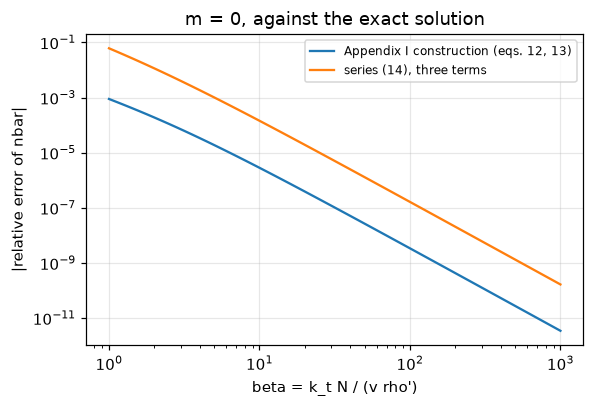

The exact series is $2\bar n = 1 + \alpha -0.333333\alpha^2 +0.166667\alpha^3 -0.088889\alpha^4 + \cdots$ ($\alpha = 1/\beta$): 3 of the 3 printed coefficients of (14) are exact, so (14) is exact to second order and the next coefficient, 1/6, is not printed. The Appendix construction ($N_2 = N_0/2\beta$ exact, eq. 13 from $n$ = 3 on) has the series $1 + 1.000000\alpha -0.333333\alpha^2 +0.163194\alpha^3$: 3 of its first 4 coefficients are exact. Its $N_1/N_0 = (4+6\beta)/(1+6\beta)$ is -6.32e-06 (relative) from the exact 1.04918696 at $\beta$ = 10, where the exact $N_2/N_0$ is 0.050000.

The relative error of $\bar n$ decreases with $\beta$ over 1 to 1000 for both (yes), so the largest is at $\beta$ = 1, the end of the range: -8.904e-04 for the Appendix construction and -6.137e-02 for the series; at $\beta$ = 10, -2.84e-06 and -1.44e-04.

In [7]:
betas, e_app, e_ser = M["_r2"]
plt.figure(figsize=(5.5, 3.8))
plt.loglog(betas, np.abs(e_app), label="Appendix I construction (eqs. 12, 13)")
plt.loglog(betas, np.abs(e_ser), label="series (14), three terms")
plt.xlabel("beta = k_t N / (v rho')")
plt.ylabel("|relative error of nbar|")
plt.title("m = 0, against the exact solution")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

say("The exact series is $2\\bar n = 1 + \\alpha <<c2:+.6f>>\\alpha^2 <<c3:+.6f>>\\alpha^3 "
    "<<c4:+.6f>>\\alpha^4 + \\cdots$ ($\\alpha = 1/\\beta$): <<np:d>> of the 3 printed coefficients of "
    "(14) are exact, so (14) is exact to second order and the next coefficient, 1/6, is not printed. "
    "The Appendix construction ($N_2 = N_0/2\\beta$ exact, eq. 13 from $n$ = 3 on) has the "
    "series $1 + <<a1:.6f>>\\alpha <<a2:+.6f>>\\alpha^2 <<a3:+.6f>>\\alpha^3$: <<na:d>> of its first 4 "
    "coefficients are exact. Its $N_1/N_0 = (4+6\\beta)/(1+6\\beta)$ is <<g:.2e>> (relative) from the "
    "exact <<p1:.8f>> at $\\beta$ = 10, where the exact $N_2/N_0$ is <<p2:.6f>>.",
    c2=M["r2_exact_c2"], c3=M["r2_exact_c3"], c4=M["r2_exact_c4"], np=M["r2_n_printed_coef_exact"],
    a1=M["r2_appendix_c1"], a2=M["r2_appendix_c2"], a3=M["r2_appendix_c3"], na=M["r2_n_appendix_coef_exact"],
    g=M["r2_p1_over_p0_gap"], p1=M["r2_p1_over_p0_exact"], p2=M["r2_p2_over_p0"])
say("The relative error of $\\bar n$ decreases with $\\beta$ over 1 to 1000 for both "
    "(<<dec>>), so the largest is at $\\beta$ = 1, the end of the range: <<ea:.3e>> for the Appendix "
    "construction and <<es:.3e>> for the series; at $\\beta$ = 10, <<ea10:.2e>> and <<es10:.2e>>.",
    dec="yes" if M["r2_errors_decrease"] else "no", ea=M["r2_appendix_err_beta1"],
    es=M["r2_series_err_beta1"], ea10=M["r2_appendix_err_beta10"], es10=M["r2_series_err_beta10"])

### R3: the upper bound (eq. 26) and the exponents

In [8]:
say("The constant of eq. 26 is exactly $5^{3/5}/(3(4\\pi)^{1/5})$ = <<k:.6f>>, <<h:.2f>> half-units "
    "from the printed 0.53. The constant of eq. 30, $(4\\pi)^{1/3}3^{2/3}\\Gamma(5/3)$ = <<c:.6f>>, is "
    "<<hc:.2f>> half-units from the printed 4.36: it rounds to 4.37, so the printed value is "
    "truncated. Scaled, the upper bound ends Stage I at $t_1/t^\\ast$ = <<t:.6f>>.",
    k=M["r3_k_upper"], h=M["r3_hu_k_upper"], c=M["r3_c_y"], hc=M["r3_hu_c_y"], t=M["r3_ts1_upper"])
say("**Exponents.** Dimensional analysis alone ($N$ per cm$^3$, $\\rho$ per cm$^3$ s, $\\mu$ "
    "cm$^3$/s, $a_sS$ per cm) leaves $N = k\\rho^x\\mu^{-x}(a_sS)^{3-6x}$ with one free exponent. "
    "An area law $a \\propto (t-\\tau)^q$ gives $N \\propto \\rho^{q/(q+1)}(a_sS)^{1/(q+1)}$, and the "
    "Case 2 sphere ($q$ = 2/3) fixes $\\rho$ <<x:.6f>>, $a_sS$ <<z:.6f>>, $\\mu$ <<y:.6f>>, "
    "<<n:d>> of 3 as printed, with the dimensional residual <<d:.0e>>. The exponents rest on "
    "the growth premise alone, not on the capture rule, which sets only $k$.",
    x=M["r3_exp_rho"], z=M["r3_exp_aS"], y=M["r3_exp_mu"], n=M["r3_n_exponents_as_printed"],
    d=max(M["r3_dimension_residual"], 1e-16))

The constant of eq. 26 is exactly $5^{3/5}/(3(4\pi)^{1/5})$ = 0.527738, 0.45 half-units from the printed 0.53. The constant of eq. 30, $(4\pi)^{1/3}3^{2/3}\Gamma(5/3)$ = 4.365654, is 1.13 half-units from the printed 4.36: it rounds to 4.37, so the printed value is truncated. Scaled, the upper bound ends Stage I at $t_1/t^\ast$ = 1.358655.

**Exponents.** Dimensional analysis alone ($N$ per cm$^3$, $\rho$ per cm$^3$ s, $\mu$ cm$^3$/s, $a_sS$ per cm) leaves $N = k\rho^x\mu^{-x}(a_sS)^{3-6x}$ with one free exponent. An area law $a \propto (t-\tau)^q$ gives $N \propto \rho^{q/(q+1)}(a_sS)^{1/(q+1)}$, and the Case 2 sphere ($q$ = 2/3) fixes $\rho$ 0.400000, $a_sS$ 0.600000, $\mu$ -0.400000, 3 of 3 as printed, with the dimensional residual 4e-16. The exponents rest on the growth premise alone, not on the capture rule, which sets only $k$.

### R4: the lower bound (eqs. 28 to 30, 26a)

In [9]:
say("The Laplace transform of (28) gives (29) directly. $E_{5/3}(y)$ changes sign once on "
    "[-3, 0], at $y_1$ = <<y:.6f>> (<<hy:.2f>> half-units from the printed -2.13). The five printed "
    "terms of (29) alone put the root at <<y4:.6f>> (<<hy4:.2f>> half-units): \"By using a method of "
    "successive approximation\" (p. 598) the authors must have used more: the sum to $n$ = <<k29:d>> is "
    "the shortest from which every longer sum rounds to -2.13. The $t_1$ constant "
    "$(-y_1/4.366)^{3/5}$ is <<t:.6f>> (<<ht:.2f>> half-units from the printed 0.650; from the printed "
    "2.13 and 4.36, <<tp:.6f>>, <<htp:.2f>> half-units): truncated again, 0.651 by rounding either way. "
    "The bracket of (26a) is $E_{5/3,2}(y_1)$ = <<b:.6f>> and $k$ = <<k:.6f>>, <<hk:.2f>> half-units from "
    "0.370 (the printed chain 0.650 $E_{5/3,2}$(-2.13) gives <<kp:.6f>>, <<hkp:.2f>> half-units). The "
    "printed terms to $n$ = 4 give <<b4:.6f>>, to $n$ = 3 <<b3:.6f>>, to $n$ = 2 <<b2:.6f>> ($k$ "
    "<<k2:.4f>>, <<hk2:.2f>> half-units: too few); the sum to $n$ = <<k26:d>> is the shortest from which every longer sum rounds to 0.370.",
    y=M["r4_y1"], hy=M["r4_hu_y1"], y4=M["r4_y1_n4"], hy4=M["r4_hu_y1_n4"], k29=M["r4_min_terms_29"],
    t=M["r4_t1_const"], ht=M["r4_hu_t1_const"], tp=M["r4_t1_const_from_printed"],
    htp=M["r4_hu_t1_const_from_printed"], b=M["r4_bracket"], k=M["r4_k_lower"], hk=M["r4_hu_k_lower"],
    kp=M["r4_k_lower_from_printed"], hkp=M["r4_hu_k_lower_from_printed"], b4=M["r4_bracket_n4"],
    b3=M["r4_bracket_n3"], b2=M["r4_bracket_n2"], k2=M["r4_k_lower_n2"], hk2=M["r4_hu_k_lower_n2"],
    k26=M["r4_min_terms_26a"])
say("Against the upper bound, the area bound ends Stage I <<rt:.6f>> times later with <<rk:.6f>> "
    "times the particles: only <<f:.2%>> of the radicals formed in its Stage I start a particle "
    "(the bracket itself, $N/\\rho t_1$).", rt=M["r4_ratio_t1"], rk=M["r4_ratio_k"],
    f=M["r4_fraction_making_particles"])

The Laplace transform of (28) gives (29) directly. $E_{5/3}(y)$ changes sign once on [-3, 0], at $y_1$ = -2.133743 (0.75 half-units from the printed -2.13). The five printed terms of (29) alone put the root at -2.135425 (1.09 half-units): "By using a method of successive approximation" (p. 598) the authors must have used more: the sum to $n$ = 5 is the shortest from which every longer sum rounds to -2.13. The $t_1$ constant $(-y_1/4.366)^{3/5}$ is 0.650812 (1.62 half-units from the printed 0.650; from the printed 2.13 and 4.36, 0.650633, 1.27 half-units): truncated again, 0.651 by rounding either way. The bracket of (26a) is $E_{5/3,2}(y_1)$ = 0.569137 and $k$ = 0.370401, 0.80 half-units from 0.370 (the printed chain 0.650 $E_{5/3,2}$(-2.13) gives 0.370329, 0.66 half-units). The printed terms to $n$ = 4 give 0.569192, to $n$ = 3 0.568150, to $n$ = 2 0.581642 ($k$ 0.3785, 17.08 half-units: too few); the sum to $n$ = 3 is the shortest from which every longer sum rounds to 0.370.

Against the upper bound, the area bound ends Stage I 1.233210 times later with 0.701865 times the particles: only 56.91% of the radicals formed in its Stage I start a particle (the bracket itself, $N/\rho t_1$).

### R5: Stage I as a population balance in particle volume

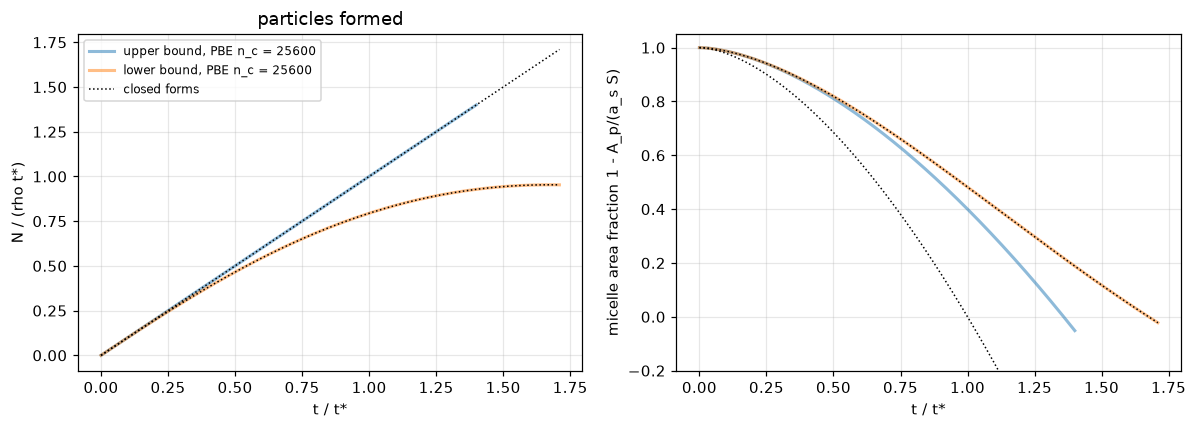

On 1600 to 25600 cells (CFL 1) the stage end, a root in time of a spline through the step values, extrapolates to $t_1/t^\ast$ = 1.358655187 (upper) and 1.675506699 (lower), and $N(t_1)/\rho t^\ast$ to 1.358655187 and 0.953593067. Against the closed forms 1.358655183 and 1.675506683 the gaps are below 1e-7, a chosen bound (here 4e-09, 2e-08, 4e-09 and 1e-08), against error estimates of the finest grid of 5.2e-05, 3.0e-05, 5.2e-05 and 5.9e-05. The largest gap is 5e-04 of its error estimate, so the plan's rule (gaps within ten error estimates) could not fail here; the bound is chosen from the gaps' size instead. The route that does not use eqs. 25a and 28 reproduces both bounds: the step from growth and nucleation to the paper's integral equation holds.

Physical scale, once: $t^\ast = (a_sS/\rho\theta)^{3/5}$ and $N = k(\rho/\mu)^{2/5}(a_sS)^{3/5}$ with $k = (4\pi)^{-1/5}3^{-2/5}N/(\rho t^\ast)$; the page uses no physical value.

In [10]:
nc = LADDER[-1]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tt = np.linspace(0, 1.71, 400)
g53 = math.gamma(5 / 3)
f_lo = mittag_leffler(-g53 * tt ** (5 / 3), 5 / 3)[0]
N_lo = tt * mittag_leffler(-g53 * tt ** (5 / 3), 5 / 3, 2.0)[0]
for b, col in (("upper", "C0"), ("lower", "C1")):
    h = pbe_run(nc, b, C0)
    ax[0].plot(h["t"], h["N"], color=col, lw=2, alpha=0.5, label=f"{b} bound, PBE n_c = {nc}")
    ax[1].plot(h["t"], 1 - h["Ap"], color=col, lw=2, alpha=0.5, label=f"{b} bound, PBE")
ax[0].plot(tt, tt, "k:", lw=1, label="closed forms")
ax[0].plot(tt, N_lo, "k:", lw=1)
ax[1].plot(tt, 1 - tt ** (5 / 3), "k:", lw=1)
ax[1].plot(tt, f_lo, "k:", lw=1)
ax[0].set(xlabel="t / t*", ylabel="N / (rho t*)", title="particles formed")
ax[1].set(xlabel="t / t*", ylabel="micelle area fraction 1 - A_p/(a_s S)", ylim=(-0.2, 1.05))
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

say("On <<l0:d>> to <<l1:d>> cells (CFL 1) the stage end, a root in time of a spline through the "
    "step values, extrapolates to $t_1/t^\\ast$ = <<tu:.9f>> (upper) and <<tl:.9f>> (lower), and "
    "$N(t_1)/\\rho t^\\ast$ to <<nu:.9f>> and <<nl:.9f>>. Against the closed forms <<cu:.9f>> and "
    "<<cl:.9f>> the gaps are below 1e-7, a chosen bound (here <<au:.0e>>, "
    "<<al:.0e>>, <<bu:.0e>> and <<bl:.0e>>), against error estimates of the finest grid of "
    "<<etu:.1e>>, <<etl:.1e>>, <<enu:.1e>> and <<enl:.1e>>. The largest gap is <<fr:.0e>> of its "
    "error estimate, so the plan's rule (gaps within ten error estimates) could not fail here; "
    "the bound is chosen from the gaps' size instead. The route "
    "that does not use eqs. 25a and 28 reproduces both bounds: the step from growth and nucleation to "
    "the paper's integral equation holds.",
    l0=LADDER[0], l1=LADDER[-1], tu=M["r5_upper_t1_ext"], tl=M["r5_lower_t1_ext"],
    nu=M["r5_upper_Nt1_ext"], nl=M["r5_lower_Nt1_ext"], cu=M["r3_ts1_upper"], cl=M["r4_ts1_lower"],
    etu=M["r5_upper_t1_err_est"], etl=M["r5_lower_t1_err_est"],
    enu=M["r5_upper_Nt1_err_est"], enl=M["r5_lower_Nt1_err_est"], au=max(M["r5_upper_t1_ext_gap"], 1e-16),
    al=max(M["r5_lower_t1_ext_gap"], 1e-16), bu=max(M["r5_upper_Nt1_ext_gap"], 1e-16),
    bl=max(M["r5_lower_Nt1_ext_gap"], 1e-16),
    fr=max(M[f"r5_{k}_ext_gap"] / M[f"r5_{k}_err_est"] for k in ("upper_t1", "lower_t1", "upper_Nt1", "lower_Nt1")))
say("Physical scale, once: $t^\\ast = (a_sS/\\rho\\theta)^{3/5}$ and $N = k(\\rho/\\mu)^{2/5}(a_sS)^{3/5}$ "
    "with $k = (4\\pi)^{-1/5}3^{-2/5}N/(\\rho t^\\ast)$; the page uses no physical value.")

## Validation

None of these uses data; there is none.

In [11]:
say("**V1 recursion.** At T the truncated recursion ($n_{max}$ = <<nm:d>>, chosen so that "
    "$p_{n_{max}}/\\max p < 10^{-17}$) meets the closed form in $\\bar n$, $p_0$, $p_1$ to <<g:.0e>>, and "
    "at <<npts:d>> map points ($m$ = 0 to 10, $\\alpha$ = 1e-4 to 1e4) to <<gm:.0e>>. The radical "
    "balance closes to <<rb:.0e>>, $\\sum p$ = 1 to <<sp:.0e>>, the replaced equation's residual is "
    "<<r0:.0e>>. Truncation error of $\\bar n$ at $n_{max}$ = 3, 4, 5: <<e3:.4e>>, <<e4:.4e>>, "
    "<<e5:.4e>> (round-off by 8: <<e8:.0e>>): super-exponential, so no order is fitted. At "
    "$\\alpha$ = 1e4 the distribution needs $n_{max}$ = <<n4:d>>. Dense LAPACK against a sparse LU "
    "with another ordering: <<cg:.0e>>.",
    nm=M["v1_T_nmax"], g=max(M["v1_T_gap"], 1e-16), npts=M["v1_map_n_points"], gm=max(M["v1_map_gap_max"], 1e-16),
    rb=max(M["v1_radical_balance"], 1e-17), sp=max(M["v1_sum_p"], 1e-17), r0=max(M["v1_eq0_residual_max"], 1e-17),
    e3=M["v1_trunc_err_3"], e4=M["v1_trunc_err_4"], e5=M["v1_trunc_err_5"], e8=max(M["v1_trunc_err_8"], 1e-17),
    n4=M["v1_nmax_alpha1e4"], cg=max(M["v1_companion_gap"], 1e-17))
say("**V2 limits.** Case 1: $\\bar n m/\\alpha$ = 1 to <<c1:.1e>> at $\\alpha$ = 1e-8. Case 2 at "
    "$m$ = 0: $(\\bar n - 1/2)/(\\alpha/2)$ = 1 to <<c2:.1e>>. Case 3 offset at $\\alpha$ = 1e4, "
    "$m$ = 0.01: <<o:.6f>> against the limit $(1-2m)/8$ = <<ol:.4f>>. Half-integer $m$: the tanh form "
    "($m$ = 1/2) to <<h1:.0e>>, the coth form ($m$ = 3/2) to <<h3:.0e>>, the slope at $m$ = 1/2 to "
    "<<hs:.0e>>.", c1=M["v2_case1_limit_gap"], c2=M["v2_case2_limit_gap"], o=M["v2_case3_offset"],
    ol=M["v2_case3_offset_limit"], h1=max(M["v2_m_half_gap"], 1e-16), h3=max(M["v2_m_three_half_gap"], 1e-16),
    hs=max(M["v2_slope_m_half_gap"], 1e-16))
_ord = [M[f"v3_{k}_order_{e}"] for k in ("upper_Ap1", "lower_Ap1", "lower_N1", "upper_t1", "lower_t1",
                                         "upper_Nt1", "lower_Nt1") for e in ("min", "max")]
say("**V3 Stage I.** The Mittag-Leffler series stops with a last term of <<lt:.0e>> at $y$ = -3. On the "
    "ladder <<l0:d>> to <<l1:d>> cells the observed orders of $A_p(1)$, $N(1)$, $t_1$ and $N(t_1)$ lie "
    "between <<omin:.4f>> and <<omax:.4f>> (theory 1). The upper-bound $N(t) = t$ holds to <<cons:.0e>> "
    "(number conservation of the scheme, not an order). The finest difference is <<rf:.1e>> times its "
    "round-off companion (the finest level with a Sherman-Morrison factorisation).",
    lt=M["r4_ml_last_term"], l0=LADDER[0], l1=LADDER[-1], omin=min(_ord), omax=max(_ord),
    cons=max(M["v3_upper_N_conservation"], 1e-16), rf=M["v3_finest_over_roundoff"])
say("**V4 check values.** <<n:d>> values from a second route agree, each inside its own tolerance.",
    n=len(DEV))

**V1 recursion.** At T the truncated recursion ($n_{max}$ = 21, chosen so that $p_{n_{max}}/\max p < 10^{-17}$) meets the closed form in $\bar n$, $p_0$, $p_1$ to 4e-16, and at 119 map points ($m$ = 0 to 10, $\alpha$ = 1e-4 to 1e4) to 5e-14. The radical balance closes to 1e-17, $\sum p$ = 1 to 1e-17, the replaced equation's residual is 1e-17. Truncation error of $\bar n$ at $n_{max}$ = 3, 4, 5: 1.5761e-04, -1.3469e-06, 6.3529e-09 (round-off by 8: 1e-17): super-exponential, so no order is fitted. At $\alpha$ = 1e4 the distribution needs $n_{max}$ = 142. Dense LAPACK against a sparse LU with another ordering: 3e-16.

**V2 limits.** Case 1: $\bar n m/\alpha$ = 1 to 2.0e-06 at $\alpha$ = 1e-8. Case 2 at $m$ = 0: $(\bar n - 1/2)/(\alpha/2)$ = 1 to 2.8e-08. Case 3 offset at $\alpha$ = 1e4, $m$ = 0.01: 0.122824 against the limit $(1-2m)/8$ = 0.1225. Half-integer $m$: the tanh form ($m$ = 1/2) to 4e-16, the coth form ($m$ = 3/2) to 2e-16, the slope at $m$ = 1/2 to 6e-16.

**V3 Stage I.** The Mittag-Leffler series stops with a last term of 9e-19 at $y$ = -3. On the ladder 1600 to 25600 cells the observed orders of $A_p(1)$, $N(1)$, $t_1$ and $N(t_1)$ lie between 0.9973 and 1.0025 (theory 1). The upper-bound $N(t) = t$ holds to 4e-14 (number conservation of the scheme, not an order). The finest difference is 1.7e+11 times its round-off companion (the finest level with a Sherman-Morrison factorisation).

**V4 check values.** 59 values from a second route agree, each inside its own tolerance.

### The claims

In [12]:
RTOL = 1e-6
ORDER_KEYS = ("upper_Ap1", "lower_Ap1", "lower_N1", "upper_t1", "lower_t1", "upper_Nt1", "lower_Nt1")
STRUCTURAL = {"v1_sum_p": "sum p = 1 is the replaced equation itself",
              "v2_case3_offset_limit": "(1 - 2m)/8 at m = 0.01, a formula",
              "r1_eq7_limit": "1/(1 + m) at m = 0.01, a formula",
              "v3_upper_N_conservation": "the upwind scheme conserves number: N = t for unit inflow",
              "r1_scan_n_m": "number of scanned m values",
              "r1_scan_n_below_half": "scanned m values below 1/2", "v1_map_n_points": "7 m values times 17 alpha values",
              "r34_n_printed": "five printed Stage I constants",
              "r5_upper_Ap1_exact": "1/(q + 1), a formula"}
BOUNDS = {"v1_T_gap": (None, 1e-12, "identity", "recursion against closed form (plan stop rule)"),
          "v1_map_gap_max": (None, 1e-11, "identity", "recursion against closed form over the map"),
          "v1_sum_p": (None, 1e-14, "identity", STRUCTURAL["v1_sum_p"]),
          "v1_radical_balance": (None, 1e-15, "identity", "alpha(1 - p_nmax) = m nbar + 2 sum n(n-1) p_n"),
          "v1_eq0_residual_max": (None, 1e-14, "identity", "sum of eq. 1 over n is zero"),
          "v1_trunc_err_8": (None, 1e-14, "theory", "truncation below round-off by n_max 8"),
          "v1_companion_gap": (None, 1e-13, "chosen", "round-off of a 22-unknown solve"),
          "v2_case1_limit_gap": (None, 1e-5, "theory", "Case 1 limit, deviation O(alpha/m)"),
          "v2_case2_limit_gap": (None, 1e-5, "theory", "Case 2 limit, deviation O(alpha)"),
          "v2_m_half_gap": (None, 1e-13, "identity", "I_(1/2)/I_(-1/2) = tanh"),
          "v2_m_three_half_gap": (None, 1e-13, "identity", "I_(3/2)/I_(1/2) = coth - 1/a"),
          "v2_slope_m_half_gap": (None, 1e-13, "identity", "closed slope at m = 1/2"),
          "r3_dimension_residual": (None, 1e-14, "identity", "N in cm^-3 from rho, mu, a_s S"),
          "r4_ml_last_term": (None, 1e-16, "tolerance", "series stopped below 1e-17 relative"),
          "v3_upper_N_conservation": (None, 1e-12, "identity", STRUCTURAL["v3_upper_N_conservation"]),
          "v3_finest_over_roundoff": (100.0, None, "chosen", "plan: finest difference 100 times round-off"),
          "r1_asym_gap": (None, 1e-3, "chosen", "asymptote of the slope: O(1/a) remainder and round-off at a = 3e5")}
for k in ORDER_KEYS:
    BOUNDS[f"v3_{k}_order_min"] = (0.9, 1.1, "theory", "first-order upwind and implicit Euler: 1")
    BOUNDS[f"v3_{k}_order_max"] = (0.9, 1.1, "theory", "first-order upwind and implicit Euler: 1")
    BOUNDS[f"r5_{k}_ext_gap"] = (None, 1e-7, "chosen", "Richardson remainder O(dv^2) on 12800 and 25600 cells; the plan's ten error estimates could not fail")
EXACT = {"r1_scan_n_m", "r1_scan_n_below_half", "r1_scan_n_min", "r1_scan_n_min_at_or_above_half", "r1_scan_n_at_or_above_half", "r2_n_printed_coef_exact",
         "r2_n_appendix_coef_exact", "r2_errors_decrease", "v1_T_nmax", "v1_nmax_alpha1e4",
         "v1_map_n_points", "r3_n_exponents_as_printed", "r34_n_printed", "r4_min_terms_29",
         "r4_min_terms_26a"}
COUNTS = {"r34_n_round": 0.05}
SKIP = {"r5_upper_t1_err_est", "r5_lower_t1_err_est", "r5_upper_Nt1_err_est", "r5_lower_Nt1_err_est",
        "r5_upper_Ap1_err_est", "r5_lower_Ap1_err_est", "r5_lower_N1_err_est"}


def register(M):
    """Register every reported number with its kind."""
    for name, v in M.items():
        if name.startswith("_") or name.endswith("__margin"):
            continue
        if name in SKIP:
            continue
        if name in BOUNDS:
            lo, hi, basis, note = BOUNDS[name]
            claims.bound(name, v, min=lo, max=hi, basis=basis, structural=name in STRUCTURAL, note=note)
        elif name in STRUCTURAL:
            if isinstance(v, (int, bool, np.integer)):
                claims.exact(name, v, structural=True, note=STRUCTURAL[name])
            else:
                claims.value(name, v, rtol=RTOL, note="structural: " + STRUCTURAL[name])
        elif name in COUNTS:
            claims.exact(name, v, margin=M[name + "__margin"], min_margin=COUNTS[name])
        elif name in EXACT:
            claims.exact(name, v)
        else:
            claims.value(name, v, rtol=1e-9 if name.startswith("r5_1600_") else RTOL)
    for name in ("r1_eq7_limit", "v2_case3_offset_limit", "r5_upper_Ap1_exact"):
        claims.metrics[name]["structural"] = True


register(M)
for k in ORDER_KEYS:     # the error estimates are printed beside the gaps; their size is the ladder's
    claims.bound(f"r5_{k}_err_est", M[f"r5_{k}_err_est"], max=1e-4, basis="chosen",
                 note="Richardson error estimate on 1600 to 25600 cells")

### The break table

Every non-structural number registered above has a row that moves it. Each row injects
one defect through `Cfg` (a rate law, a reading of the paper, a printed entry, a solver or
grid setting) and reruns the parts of the study the defect reaches; the claims it fails
are counted. Only finite values are recorded; a row under which the study raises is
listed as a crash. Two rows remove the root that ends Stage I: under them the flux has no
sign change on the whole scanned range (shown by the scan, and for $E_{2/3}$ by its
complete monotonicity), and the claims that need $y_1$ record nan (rule 11). The row that
takes $A_p/A$ in (21a) records nan for the stage end: $A_p(0) = 0$, so nothing nucleates.
The control fails nothing.

In [13]:
def printed_row(item, new, parts):
    """A break row that mistypes one printed entry."""
    pn = PN.copy()
    i = pn.index[pn["item"] == item][0]
    old = pn.at[i, "printed"]
    pn.at[i, "printed"] = new
    return f"printed {item} {old} -> {new}", replace(C0, pn=pn), parts


P1, ST, PB = ("p1",), ("stage",), ("stage", "pbe1600")
DEFECTS = [
    ("termination counted as 2 k_t (alpha doubled)", replace(C0, law=Law(term=2.0)), ("p1", "rec")),
    ("desorption k_0 a/v, not proportional to n", replace(C0, law=Law(desorb="constant")), ("p1", "rec")),
    ("truncation leaks entry out of n_max", replace(C0, law=Law(leak=True)), ("rec",)),
    ("n_max = 3 called converged", replace(C0, nmax_cap=3), ("rec",)),
    ("eq. 13 also at n = 2", replace(C0, law=Law()), ("p1",)),
    ("m scan of 13 values, not 25", replace(C0, scan_n=13), P1),
    ("(4 pi)^(1/3) inside eq. 22", replace(C0, stage=Stage(pi_exp=1 / 3)), ST),
    ("kernel (t - tau)^(1/3)", replace(C0, stage=Stage(q=1 / 3)), PB),
    ("Gamma(1 + 2n/3) in (29)", replace(C0, stage=Stage(ml_a=2 / 3)), ST),
    ("(26a) to n = 2", replace(C0, stage=Stage(n26a=2)), ST),
    ("PBE inflow lagged one step", replace(C0, lag=True), PB),
    ("PBE cell-centre weights v_i^(2/3)", replace(C0, weights="centre"), PB),
    ("eq. 8 without re-entry (rho' = rho)", replace(C0, reentry=False), P1),
    ("A_p/A in place of A_m/A in (21a)", replace(C0, stage=Stage(capture="particle")), PB),
    ("Case 1 and 2 limits at alpha = 1e-3", replace(C0, lim_alpha=1e-3), P1),
    ("recursion companion at alpha 1e-9 high", replace(C0, comp_alpha=1 + 1e-9), ("rec",)),
    ("PBE ladder 200 to 3200 cells (pre-asymptotic)", replace(C0, ladder=(200, 400, 800, 1600, 3200)), ("stage", "ladder")),
    ("Mittag-Leffler series stopped at 1e-8", replace(C0, stage=Stage(ml_tol=1e-8)), ST),
    ("PBE inflow off by 50 dv^(1/2) % (grid-dependent)", replace(C0, inflow_defect=0.5), ("stage", "ladder")),
    ("PBE companion with inflow 1e-6 high", replace(C0, comp_scale=1 + 1e-6), ("comp",)),
    printed_row("c_y_eq30", "4.38", ST),
    printed_row("y1", "-2.15", ST),
    printed_row("t1_const", "0.660", ST),
    printed_row("k_lower_eq26a", "0.380", ST),
    printed_row("k_upper_eq26", "0.55", ST),
    printed_row("k_bracket_lo", "0.36", ST),
    printed_row("k_bracket_hi", "0.52", ST),
    printed_row("exp_rho", "1/2", ST),
    printed_row("eq14_c2", "-1/4", P1),
    printed_row("beta_condition", "10", P1),
]
# the eq. 13 row runs the construction from n = 2; it is a reading of Appendix I, so it is
# injected by wrapping the two construction functions the study calls
EQ13_ROW = "eq. 13 also at n = 2"
CONTROLS = [("control: clean rerun of the cheap parts", C0, ("p1", "stage"))]
claims.define_rows([r_ for r_, _, _ in CONTROLS + DEFECTS])
BREAK, CRASH = [], set()
_app_nbar, _app_series = appendix_nbar, appendix_series
for row, c_, parts in CONTROLS + DEFECTS:
    if row == EQ13_ROW:
        appendix_nbar = lambda b, eq13_from=2, nterms=40: _app_nbar(b, eq13_from=2, nterms=nterms)
        appendix_series = lambda K=4, eq13_from=2: _app_series(K, eq13_from=2)
    try:
        with np.errstate(divide="ignore", invalid="ignore"):
            Mb = study(c_, parts)
    except (ValueError, RuntimeError, np.linalg.LinAlgError, IndexError, TypeError) as e:
        print(f"{row}: {type(e).__name__}: {e}")
        Mb = {}
    finally:
        appendix_nbar, appendix_series = _app_nbar, _app_series
    noroot = bool(Mb.get("_noroot", False))
    for name in claims.metrics:
        if claims.metrics[name].get("structural"):
            continue
        x_ = Mb.get(name, None)
        if x_ is None:
            continue
        if isinstance(x_, (float, np.floating)) and not np.isfinite(x_) and not noroot:
            continue                  # only finite values, except a shown non-existence (rule 11)
        BREAK.append((row, name, claims.breaks(row, name, x_)))
    if not any(name in Mb for name in claims.metrics):
        CRASH.add(row)

In [14]:
# The break table: one line per row, with the claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<52} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:52]:<52} {sum(cs):13d}")
_caught = {m_ for r_, m_, c_ in BREAK if c_ and r_ not in CRASH}
print(f"rows that only crash: {', '.join(sorted(CRASH)) or 'none'}")
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught
               and not claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; open: {', '.join(_open) or 'none'}")

injected defect                                      claims failed
control: clean rerun of the cheap parts                          0
termination counted as 2 k_t (alpha doubled)                    56
desorption k_0 a/v, not proportional to n                       22
truncation leaks entry out of n_max                              4
n_max = 3 called converged                                       7
eq. 13 also at n = 2                                            10
m scan of 13 values, not 25                                      2
(4 pi)^(1/3) inside eq. 22                                      15
kernel (t - tau)^(1/3)                                          46
Gamma(1 + 2n/3) in (29)                                         12
(26a) to n = 2                                                   9
PBE inflow lagged one step                                       4
PBE cell-centre weights v_i^(2/3)                                7
eq. 8 without re-entry (rho' = rho)                           

## What pymrm adds

Not the model: eq. 1, its limits and the Stage I bounds are the paper's, the exact
solution of eq. 1 is later work in closed form, and the Stage I constants are
Mittag-Leffler series; those are scipy and exact arithmetic, and the recursion is a
linear sparse solve with no Newton iteration. pymrm contributes the second Stage I route
and the checks. The population balance in particle volume uses
`construct_convflux_upwind` with the nucleation rate as an external inflow value
(`shapes_d`, assembled once), `construct_div`, and `pymrm.newton` for each implicit
Euler step with the analytic Jacobian (bidiagonal plus one dense row from the nonlocal
inflow). It is the route that does not use eqs. 25a and 28, so it tests the paper's step
from growth and nucleation to its integral equation. `pymrm.checks.find_roots` gives
every case boundary, the plateau threshold, the eq. 8 state, $y_1$ and the stage end as
the only root on its range; `pymrm.checks.observed_orders` gives the orders and the
extrapolated stage end.

## Reuse

- `model.nbar_closed(alpha, m)` is the exact mean radical number for any entry and
  desorption group (desorption proportional to $n$, no re-entry unless added as in A3);
  `model.recursion` handles other laws, at the cost of a truncation level.
- The Case 2 premise is a statement about $\beta$ and $m$, not about the system: check
  $\beta \gtrsim 10$ and $m \ll 1/2$ before using $\bar n = 1/2$ or the $N$ law.
- `model.stage_closed(Stage(q=...))` gives the bounds for another area law; `StageIPBE`
  takes another nucleation rule in `inflow`, which is where a real micelle model goes.
- Related pages: `J5.3` (bulk free-radical kinetics), `J5.1` (moments), `J5.2`
  (Flory-Schulz), `J2.1` and `J2.2` (population balances), `J2.6` (coagulation).

In [15]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for J5.6:
  r1_T_nbar                      = 0.52419          value  rtol 1e-06
  r1_T_p0                        = 0.49913          value  rtol 1e-06
  r1_T_p1                        = 0.47794          value  rtol 1e-06
  r1_T_rate_over_case2           = 1.0484           value  rtol 1e-06
  r1_eq7_ratio                   = 0.99132          value  rtol 1e-06
  r1_eq7_limit                   = 0.9901           value  rtol 1e-06
  r1_T_slope                     = 0.1324           value  rtol 1e-06
  r1_beta_10pct_m0               = 9.6723           value  rtol 1e-06
  r1_beta_1pct_m0                = 99.667           value  rtol 1e-06
  r1_beta_10pct_over_condition   = 9.6723           value  rtol 1e-06
  r1_alpha_case3_10pct_m0        = 4.2012           value  rtol 1e-06
  r1_alpha_case1_10pct           = 0.00056142       value  rtol 1e-06
  r1_alpha_nbar_045              = 0.032937         value  rtol 1e-06
  r1_alpha_nbar_055              = 0.14137          value  rtol 1e-06
  r